## Análisis - Hallazgos

- Principales hallazgos, organizados por pregunta de negocio

### Imports

In [1]:
import os, socket
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 200)

### Utilidades

- Constantes

In [2]:
proyecto = Path.cwd()
while not (proyecto / "docker-compose.yml").exists() and proyecto != proyecto.parent:
    proyecto = proyecto.parent
out_dir = proyecto / "06_Analisis" / "temp" / "b_hallazgos"
out_dir.mkdir(parents=True, exist_ok=True)

- Lectura de resultados

In [3]:
def leer(modulo, nb, tabla):
    ruta = proyecto / modulo / "temp" / nb / "tablas" / tabla
    assert ruta.exists(), f"No se encuentra {ruta}; corre {modulo}/{nb}.ipynb"
    return spark.read.parquet(str(ruta)).toPandas()

- Figuras y tablas

In [ ]:
def mostrar_fig(nombre):
    plt.tight_layout()
    plt.savefig(fig_dir / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()


def guardar_tabla(df, nombre):
    sdf = spark.createDataFrame(df) if isinstance(df, pd.DataFrame) else df
    sdf.coalesce(1).write.mode("overwrite").parquet(str(tab_dir / nombre))
    sdf.toPandas().to_json(web_dir / f"{nombre}.json", orient="records", force_ascii=False, date_format="iso", indent=1)
    return len(df) if isinstance(df, pd.DataFrame) else sdf.count()


def dirs_salida(out_dir):
    fig_dir, tab_dir, web_dir = out_dir / "figs", out_dir / "tablas", out_dir / "web"
    for d in (fig_dir, tab_dir, web_dir):
        d.mkdir(parents=True, exist_ok=True)
    return fig_dir, tab_dir, web_dir


fig_dir, tab_dir, web_dir = dirs_salida(out_dir)

- Spark

In [5]:
spark_master = os.environ.get("spark_master", "local[*]")

builder = (SparkSession.builder
           .appName("analisis-hallazgos")
           .master(spark_master)
           .config("spark.driver.memory",   os.environ.get("SPARK_DRIVER_MEMORY", "2g"))
           .config("spark.executor.memory", os.environ.get("SPARK_EXECUTOR_MEMORY", "2g"))
           .config("spark.sql.shuffle.partitions", "8")
           .config("spark.ui.showConsoleProgress", "false")
           .config("spark.sql.session.timeZone", "America/Lima"))

if spark_master.startswith("spark://"):
    builder = (builder.config("spark.driver.host", socket.gethostname())
                      .config("spark.driver.bindAddress", "0.0.0.0"))

spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

### Verificación del cluster

In [6]:
sc = spark.sparkContext
estado = sc._jsc.sc().getExecutorMemoryStatus()
print(f"Master        : {sc.master}")
print(f"Executors     : {estado.size() - 1}")
print(f"Cores totales : {sc.defaultParallelism}")
print(f"Memoria driver: {sc._jvm.java.lang.Runtime.getRuntime().maxMemory() / 1024**3:.1f} GB")
print("UI del job    : http://localhost:4040")

---
### 1. P1 - Unico postor

¿Qué combinaciones de método, monto, rubro y región se asocian a procesos con **un solo postor**?

#### a. ¿Dónde está el postor único?

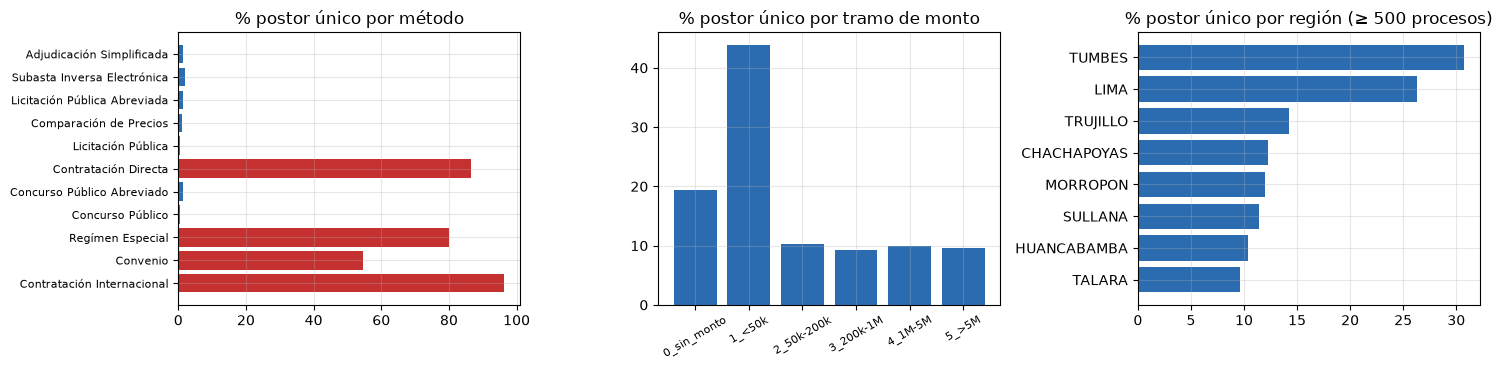

In [7]:
metodo = leer("01_EDA_KDD", "b_exploracion", "competencia_metodo").head(11)
tramo = leer("01_EDA_KDD", "a_transformaciones", "postor_unico_tramo")
region = leer("01_EDA_KDD", "b_exploracion", "competencia_region").query("procesos >= 500").head(8)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
m_ = metodo.iloc[::-1]
ax[0].barh(m_["metodo_detalle"].str[:28], m_["%_postor_unico"], color=["#c53030" if v > 50 else "#2b6cb0" for v in m_["%_postor_unico"]])
ax[0].set_title("% postor único por método"); ax[0].tick_params(axis="y", labelsize=8)
ax[1].bar(tramo["tramo_monto"], tramo["%_postor_unico"], color="#2b6cb0"); ax[1].set_title("% postor único por tramo de monto")
ax[1].tick_params(axis="x", rotation=30, labelsize=8)
r_ = region.iloc[::-1]
ax[2].barh(r_["region"], r_["pct_postor_unico"], color="#2b6cb0"); ax[2].set_title("% postor único por región (≥ 500 procesos)")
mostrar_fig("p1_postor_unico")

- Postor único es estructural: ~11% de los procesos cada año

- **El método lo explica casi todo:** Contratación Directa (86.5%), Régimen Especial (80.0%)

- Contratación Internacional (96.3%) y Convenio (54.6%), frente a 0.4–2.1% en los métodos competitivos

- **Monto:** el tramo bajo 50k concentra el postor único (43.8%)

- **Región:** Tumbes (30.7%) y Lima (26.3%) duplican el promedio nacional

#### b. Evolucion en el tiempo

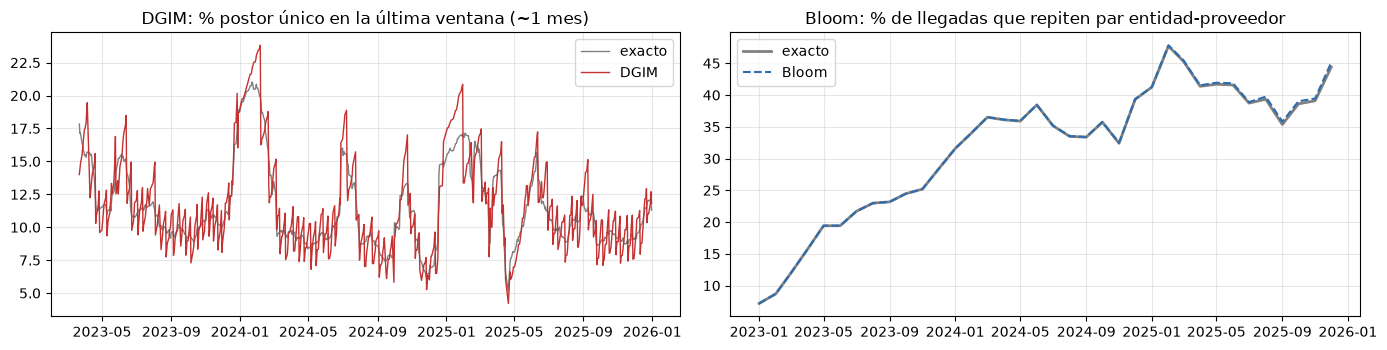

,par,llegadas,pct_postor_unico
0,primera vez,123860,11.9
1,reincidente,60369,16.3


In [8]:
serie = leer("04_Flujos", "a_dgim", "serie").query("ventana_llena")
serie["fecha"] = pd.to_datetime(serie["fecha"])
reinc = leer("04_Flujos", "b_bloom", "reincidencia_mes")
reinc["periodo"] = pd.to_datetime(reinc["anio"].astype(str) + "-" + reinc["mes"].astype(str).str.zfill(2))
post = leer("04_Flujos", "b_bloom", "postor_reincidencia")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
n_ventana = (serie["exacto"] / serie["pct_postor_unico"] * 100).median()
ax[0].plot(serie["fecha"], serie["pct_postor_unico"], color="gray", lw=1, label="exacto")
ax[0].plot(serie["fecha"], serie["estimado"] / n_ventana * 100, color="#c53030", lw=1, label="DGIM")
ax[0].set_title("DGIM: % postor único en la última ventana (~1 mes)"); ax[0].legend()
ax[1].plot(reinc["periodo"], reinc["pct_reincide_exacto"], color="gray", lw=2, label="exacto")
ax[1].plot(reinc["periodo"], reinc["pct_reincide_bloom"], color="#2b6cb0", ls="--", label="Bloom")
ax[1].set_title("Bloom: % de llegadas que repiten par entidad-proveedor"); ax[1].legend()
mostrar_fig("p1_flujos")
post

In [9]:
hh = leer("04_Flujos", "c_sketch", "heavy_hitters").head(8)
hh[["entidad", "proveedor"]] = hh["par"].str.split("|", expand=True)
hh[["entidad", "proveedor", "exacto", "estimado_conservador", "pct_postor_unico"]]

,entidad,proveedor,exacto,estimado_conservador,pct_postor_unico
0,COMISION DE PROMOCION DEL PERU PARA LA EXPORTACION Y EL TURISMO - PROMPERU,META PLATFORMS IRELAND LIMITED,155,155,100.0
1,GOBIERNO REGIONAL DE PUNO SEDE CENTRAL,GRUPO SANTA FE SOCIEDAD ANONIMA CERRADA - GRUPO SANTA FE S.A.C.,153,153,0.0
2,COMISION DE PROMOCION DEL PERU PARA LA EXPORTACION Y EL TURISMO - PROMPERU,GOOGLE LLC,128,128,100.0
3,COMISION DE PROMOCION DEL PERU PARA LA EXPORTACION Y EL TURISMO - PROMPERU,TIKTOK INC,113,113,100.0
4,SEGURO SOCIAL DE SALUD,CARDIO PERFUSION E.I.R.LTDA,73,73,30.1
5,SEGURO SOCIAL DE SALUD,DIAGNOSTICA PERUANA S.A.C.,62,62,3.2
6,GOBIERNO REGIONAL DE MADRE DE DIOS SEDE CENTRAL,GRUPO SANTA FE SOCIEDAD ANONIMA CERRADA - GRUPO SANTA FE S.A.C.,58,58,0.0
7,MTC-PROYECTO ESPECIAL DE INFRAESTRUCTURA DE TRANSPORTE NACIONAL (PROVIAS NAC...,GONZALES LACA CARLOS MIGUEL,57,57,100.0


- **Estacionalidad (DGIM):** el postor único sube en enero y diciembre, y baja en abril y noviembre

- **Reincidencia (Bloom):** un tercio de las llegadas repite un par entidad-proveedor ya visto

- **Los pares reincidentes tienen más postor único** que en su primera aparición (16.3% vs 11.9%)

- **Pares más frecuentes (Count-Min):** PROMPERÚ con Meta, Google y TikTok (100% postor único, publicidad digital) 

- PROVIAS con una persona natural; GORE Puno con Grupo Santa Fe (0%), proveedores dominantes en procesos competitivos

#### c. Combinaciones que predicen

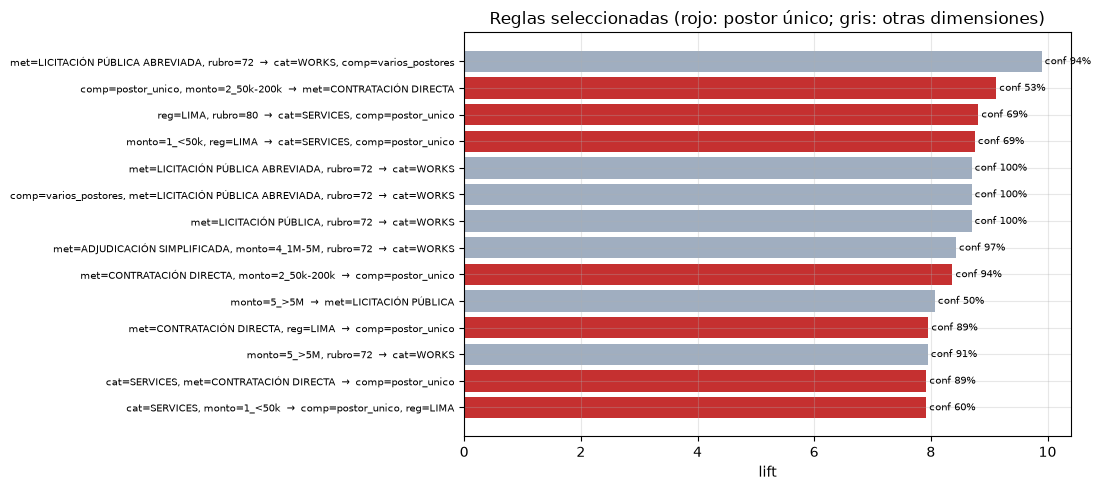

,regla,soporte,confianza,lift,estable_en_q4
0,"comp=postor_unico, monto=2_50k-200k → met=CONTRATACIÓN DIRECTA",0.023,0.531,9.121,False
1,"reg=LIMA, rubro=80 → cat=SERVICES, comp=postor_unico",0.029,0.694,8.815,False
2,"monto=1_<50k, reg=LIMA → cat=SERVICES, comp=postor_unico",0.024,0.689,8.755,False
3,"met=CONTRATACIÓN DIRECTA, monto=2_50k-200k → comp=postor_unico",0.023,0.936,8.371,False
4,"met=CONTRATACIÓN DIRECTA, reg=LIMA → comp=postor_unico",0.026,0.890,7.958,True
5,"cat=SERVICES, met=CONTRATACIÓN DIRECTA → comp=postor_unico",0.032,0.886,7.923,True
6,"cat=SERVICES, monto=1_<50k → comp=postor_unico, reg=LIMA",0.024,0.601,7.920,False


In [10]:
reglas = leer("05_Asociacion", "d_analisis", "seleccion")
reglas["regla"] = reglas["antecedente"].map(lambda a: ", ".join(a)) + "  →  " + reglas["consecuente"].map(lambda c: ", ".join(c))
r_ = reglas.sort_values("lift")
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(r_["regla"].str[:85], r_["lift"], color=["#c53030" if g == "p1" else "#a0aec0" for g in r_["grupo"]])
for y_, (l_, c_) in enumerate(zip(r_["lift"], r_["confianza"])):
    ax.annotate(f" conf {c_:.0%}", (l_, y_), va="center", fontsize=7)
ax.tick_params(axis="y", labelsize=7); ax.set_xlabel("lift")
ax.set_title("Reglas seleccionadas (rojo: postor único; gris: otras dimensiones)")
mostrar_fig("p1_reglas")
reglas.query("grupo == 'p1'")[["regla", "soporte", "confianza", "lift", "estable_en_q4"]].round(3)

- **Método + monto** es la combinación más fuerte: `{Contratación Directa, 50k–200k} → postor único`

- **Método + región / categoría:** Contratación Directa en Lima (89.0%) o en servicios (88.6%)

- **Lima + servicios** aparece en varias reglas: servicios profesionales (`rubro=80`) o montos bajo 50k

- **Contraste:** un método competitivo en obras (`Licitación Pública Abreviada + rubro 72`) da **varios postores**

#### d. Hallazgo 

- La baja competencia se explica por el método (Contratación Directa, Régimen Especial, Convenio)

- Se concentra en montos bajos, en Lima y Tumbes, en enero/diciembre y en pares entidad-proveedor que se repiten

### 2. P2 — Fraccionamiento

¿Hay procesos **casi idénticos** de una misma entidad, en fechas cercanas y con montos bajos, que sugieran dividir una compra para evadir un método más exigente?

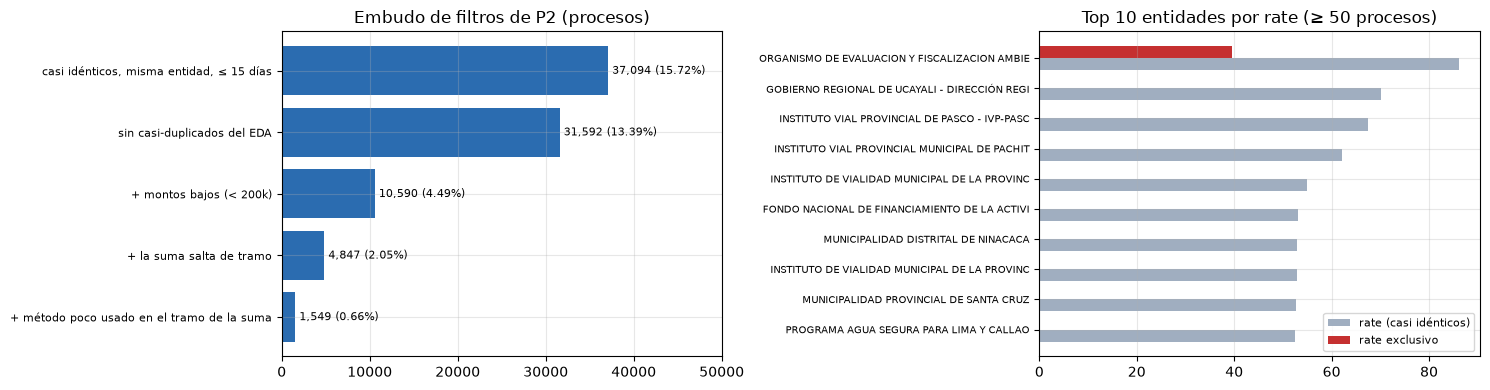

In [11]:
embudo = leer("02_Similitud", "d_entidades", "embudo_exclusivo")
ranking = leer("02_Similitud", "d_entidades", "ranking").head(10)

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
e_ = embudo.iloc[::-1]
ax[0].barh(e_["nivel"].str.replace(r"^\d\. ", "", regex=True).str[:48], e_["procesos"], color="#2b6cb0"); ax[0].set_xlim(0, e_["procesos"].max() * 1.35)
for y_, (p_, pct) in enumerate(zip(e_["procesos"], e_["pct_procesos"])):
    ax[0].annotate(f" {p_:,} ({pct}%)", (p_, y_), va="center", fontsize=8)
ax[0].set_title("Embudo de filtros de P2 (procesos)"); ax[0].tick_params(axis="y", labelsize=8)
r_ = ranking.iloc[::-1]; y = np.arange(len(r_))
ax[1].barh(y - .2, r_["rate"] * 100, .4, color="#a0aec0", label="rate (casi idénticos)")
ax[1].barh(y + .2, r_["rate_exclusivo"] * 100, .4, color="#c53030", label="rate exclusivo")
ax[1].set_yticks(y); ax[1].set_yticklabels(r_["entidad"].str[:45], fontsize=7); ax[1].legend(fontsize=8)
ax[1].set_title("Top 10 entidades por rate (≥ 50 procesos)")
mostrar_fig("p2_fraccionamiento")

- **Repetir compras es común:** 1 de cada 6 procesos (15.7%) tiene un casi idéntico de la misma entidad a ≤ 15 días

- **El patrón completo es raro:** montos bajos, salto de tramo y método poco usado quedan **1,549 procesos**

- **OEFA concentra el 90%** (1,388): grupos de hasta 481 servicios de terceros por Régimen Especial el mismo día

- **Sin OEFA** quedan 161 procesos en 32 entidades, casi siempre por Convenio en unidades de proyectos

- **Rate alto no es fraccionamiento:** institutos viales repiten 50–67% de sus procesos, sin ningún proceso exclusivo

### 3. P3 — Precios de referencia

Para procesos de **objeto parecido** (misma categoría, descripción similar), ¿cuánto varía el monto contratado?

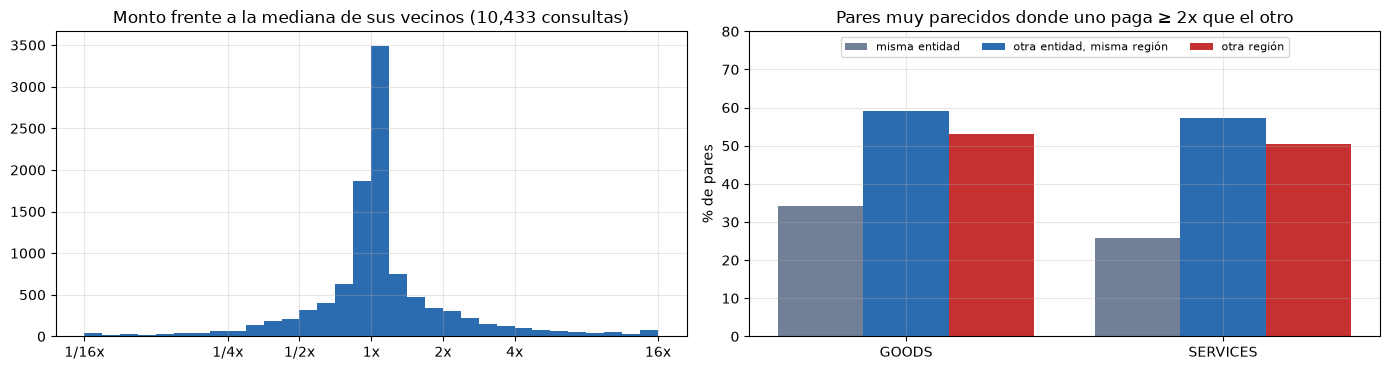

Mediana del ratio: 1.00x | p25–p75: 0.90x–1.25x | ≥ 2x: 12.1% | ≥ 5x: 3.3%


In [12]:
var = leer("03_ANN", "e_analisis", "variacion_monto")
cruce = leer("03_ANN", "e_analisis", "otra_region")
l2 = np.log2(var["ratio"]).clip(-4, 4)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].hist(l2, bins=np.arange(-4, 4.1, .25), color="#2b6cb0")
ax[0].set_xticks([-4, -2, -1, 0, 1, 2, 4]); ax[0].set_xticklabels(["1/16x", "1/4x", "1/2x", "1x", "2x", "4x", "16x"])
ax[0].set_title(f"Monto frente a la mediana de sus vecinos ({len(var):,} consultas)")
tipos = ["misma entidad", "otra entidad, misma región", "otra región"]
cats = ["GOODS", "SERVICES"]; x = np.arange(len(cats)); w = .27
for k_, (t_, col) in enumerate(zip(tipos, ["#718096", "#2b6cb0", "#c53030"])):
    v = [cruce.query("tipo == @t_ and categoria == @c")["pct_2x_o_mas"].sum() for c in cats]
    ax[1].bar(x + (k_ - 1) * w, v, w, color=col, label=t_)
ax[1].set_xticks(x); ax[1].set_xticklabels(cats); ax[1].set_ylabel("% de pares"); ax[1].set_ylim(0, 80); ax[1].legend(fontsize=8, ncol=3, loc="upper center")
ax[1].set_title("Pares muy parecidos donde uno paga ≥ 2x que el otro")
mostrar_fig("p3_precios")
print(f"Mediana del ratio: {var['ratio'].median():.2f}x | p25–p75: {var['ratio'].quantile(.25):.2f}x–{var['ratio'].quantile(.75):.2f}x | "
      f"≥ 2x: {(var['ratio'] >= 2).mean():.1%} | ≥ 5x: {(var['ratio'] >= 5).mean():.1%}")

- **En la mayoría el monto varía poco:** la mediana paga lo mismo que sus vecinos

- **Hay una cola:** el 12% paga el doble o más que compras parecidas y el 3%, cinco veces o más

- **La diferencia es de entidad, no de región:** entre procesos parecidos de la misma entidad, 26–34%

- Con otra entidad sube a 50–59%, sea de la misma región o de otra

- **Ninguna región ni entidad paga sistemáticamente más:** las medianas van de 0.91x a 1.18x

- **Los extremos son cantidades, no precios:** leche evaporada 48–63x entre Puente Piedra y municipios rurales

### 4. Resumen de respuestas

In [13]:
respuestas = pd.DataFrame([
    {"pregunta": "P1 — Competencia", "respuesta": "Postor único ~11%, explicado por el método (Contratación Directa 86.5%) y concentrado en montos bajos, Lima/Tumbes, enero/diciembre y pares que se repiten",
     "evidencia": "EDA, DGIM, Bloom, Count-Min, reglas (conf. 93.6%)"},
    {"pregunta": "P2 — Fraccionamiento", "respuesta": "1 de cada 6 procesos tiene un casi idéntico cercano, pero solo el 0.66% cumple el patrón completo; OEFA aporta el 90%",
     "evidencia": "MinHash + LSH (recall 99.99%), embudo de filtros"},
    {"pregunta": "P3 — Precios de referencia", "respuesta": "Mediana 1x y 12% paga ≥ 2x; la diferencia aparece entre entidades distintas (escala de compra), no entre regiones",
     "evidencia": "TF-IDF + IVF (recall 75%), ratio vs vecinos"},
])
respuestas

,pregunta,respuesta,evidencia
0,P1 — Competencia,"Postor único ~11%, explicado por el método (Contratación Directa 86.5%) y co...","EDA, DGIM, Bloom, Count-Min, reglas (conf. 93.6%)"
1,P2 — Fraccionamiento,"1 de cada 6 procesos tiene un casi idéntico cercano, pero solo el 0.66% cump...","MinHash + LSH (recall 99.99%), embudo de filtros"
2,P3 — Precios de referencia,Mediana 1x y 12% paga ≥ 2x; la diferencia aparece entre entidades distintas ...,"TF-IDF + IVF (recall 75%), ratio vs vecinos"


### 5. Escritura de resultados

Tablas en `temp/b_hallazgos/tablas` y `web/`

In [14]:
tablas = {"respuestas": respuestas, "reglas_p1": reglas.query("grupo == 'p1'")[["regla", "soporte", "confianza", "lift"]]}
escritos = {nombre: guardar_tabla(df, nombre) for nombre, df in tablas.items()}
print(f"Escrito en temp/b_hallazgos/: {', '.join(escritos)}")

Escrito en temp/b_hallazgos/: respuestas, reglas_p1


#### a. Verificación

In [15]:
for nombre, n in escritos.items():
    leido = spark.read.parquet(str(tab_dir / nombre)).count()
    assert leido == n, f"{nombre}: esperaba {n}, leí {leido}"
    assert (web_dir / f"{nombre}.json").exists(), f"falta web/{nombre}.json"

figs = sorted(p.stem for p in fig_dir.glob("*.png"))
print(f"OK: {len(escritos)} tablas (parquet + json) | {len(figs)} figuras: {', '.join(figs)}")

OK: 2 tablas (parquet + json) | 5 figuras: p1_flujos, p1_postor_unico, p1_reglas, p2_fraccionamiento, p3_precios


---
### 6. Cerrar sesión

In [16]:
spark.stop()